# Audio alignment with SGPA

**Goal:** split a recorded sentence into one audio segment per word, with cuts at quiet points, so each word can later be masked as a player.

**Why it matters:** an audio explanation is only auditable when every player is a whole word; a cut inside a sound changes what the model hears and makes attributions irreproducible.

**Prerequisites:** `uv sync --extra audio --extra transformers`. The first run downloads `facebook/wav2vec2-base-960h` (about 360 MB); its load report lists `masked_spec_embed` as missing, a training-only parameter. The clip `data/voices_sp0307.wav` is from the VOiCES corpus (CC BY 4.0).

**Output:** word segments with times and confidence, then the same words as players of an explanation, with their masked audio.

In [1]:
from pathlib import Path

import numpy as np

from nlp_shap import (
    AudioPart,
    CoalitionMask,
    ConversationSnapshot,
    DeletePolicy,
    ExplainConfig,
    ExplainRunner,
    Message,
    NeutralPolicy,
    Role,
    SgpaSegmentPartitioner,
    TextPart,
    Turn,
)
from nlp_shap.alignment import (
    AudioSegment,
    SpectrogramGuidedAligner,
    Wav2Vec2Ctc,
    decode_audio,
)
from nlp_shap.viz import plot_audio_segments

## Align a sentence

`Wav2Vec2Ctc` pins the Hub revision so the segments are reproducible. `align` takes the transcript as a string or a token list and the audio as an `AudioPart`.

In [2]:
MODEL_ID = "facebook/wav2vec2-base-960h"
REVISION = "22aad52d435eb6dbaf354bdad9b0da84ce7d6156"
TRANSCRIPT = "I had that curiosity beside me at this moment"

audio = AudioPart(Path("data/voices_sp0307.wav"), sample_rate=16000)
aligner = SpectrogramGuidedAligner(Wav2Vec2Ctc(MODEL_ID, revision=REVISION))
segments = aligner.align(TRANSCRIPT, audio)


def show(rows: list[AudioSegment]) -> None:
    for s in rows:
        print(f"{s.token:10} {s.start_time:6.3f} {s.end_time:6.3f} "
              f"conf={s.confidence:.2f} refined={s.boundary_refined}")


show(segments)

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


I           0.523  0.624 conf=1.00 refined=True
had         0.624  0.885 conf=0.97 refined=True
that        0.885  1.078 conf=0.97 refined=True
curiosity   1.078  1.851 conf=0.99 refined=False
beside      1.851  2.273 conf=1.00 refined=False
me          2.273  2.515 conf=1.00 refined=True
at          2.515  2.575 conf=0.99 refined=True
this        2.575  2.780 conf=0.94 refined=True
moment      2.780  3.182 conf=0.98 refined=True


## Boundary refinement

Each boundary moves, inside the gap between two words, to the minimum of `energy_weight * RMS + flux_weight * spectral flux`, and only if that point is quiet. In the figure, dashed lines are the rough CTC edges, arrows show where refinement moved them, solid lines are the final boundaries, and the lower panel is the RMS energy whose dips the cuts land in. Neighbouring segments share their boundary, so no audio is lost or counted twice.

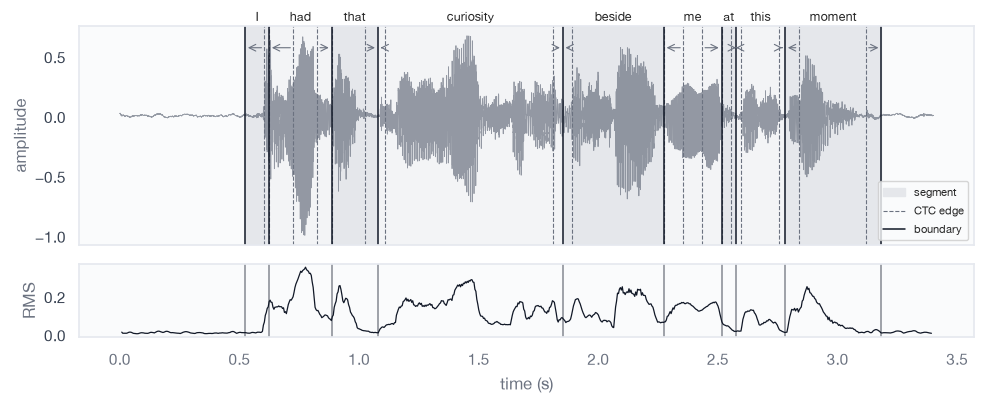

In [3]:
plot_audio_segments(audio, segments);

Weighting spectral flux only moves some cuts, but far fewer land on quiet points than with the default weights:

In [4]:
flux_only = SpectrogramGuidedAligner(aligner.model, energy_weight=0.0, flux_weight=1.0)
other = flux_only.align(TRANSCRIPT, audio)
print("refined: default", sum(s.boundary_refined for s in segments), "flux only", sum(s.boundary_refined for s in other))
print("start shift (s):", [(a.token, round(b.start_time - a.start_time, 3)) for a, b in zip(segments, other)])

refined: default 7 flux only 1
start shift (s): [('I', 0.0), ('had', 0.0), ('that', -0.03), ('curiosity', -0.012), ('beside', 0.0), ('me', 0.0), ('at', -0.04), ('this', 0.0), ('moment', 0.016)]


## Segment audio

`attach_audio=True` stores each segment as WAV bytes; this is the unit a masking policy removes or keeps.

In [5]:
with_audio = aligner.align(TRANSCRIPT, audio, attach_audio=True)
word = max(with_audio, key=lambda s: s.duration)
waveform, rate = decode_audio(word.audio)
print(word.token, f"{len(waveform) / rate:.3f} s", len(waveform) == word.end_sample - word.start_sample)

curiosity 0.773 s True


## Guards and custom models

Tokens the model cannot spell get no segment; a transcript with none, or unusable weights, raise `ValueError`. Any object with `sample_rate`, `blank_id`, `vocab` and `log_probs` is a `CtcModel`, for example a fixed matrix in a test.

In [6]:
print([s.token for s in aligner.align("I had — that", audio)][:3])
for call in (lambda: aligner.align("— …", audio),
             lambda: SpectrogramGuidedAligner(aligner.model, energy_weight=0, flux_weight=0)):
    try:
        call()
    except ValueError as error:
        print("ValueError:", error)


class FixedCtc:
    sample_rate, blank_id, vocab = 16000, 0, {"<pad>": 0, "A": 1}

    def log_probs(self, waveform: np.ndarray) -> np.ndarray:
        frames = len(waveform) // 320
        lp = np.full((frames, 2), -20.0)
        lp[:, 0] = 0.0
        lp[frames // 3 : 2 * frames // 3, :] = [-20.0, 0.0]
        return lp


show(SpectrogramGuidedAligner(FixedCtc()).align("a", audio))

['I', 'had', 'that']
ValueError: the transcript has no characters the CTC model knows
ValueError: boundary weights must be non-negative with a positive sum
a           1.080  2.260 conf=1.00 refined=True


## Words as players

`explanation.players: sgpa_segments` aligns every message that holds audio and its transcript, and makes each word a player whose span covers both. No backend generates from audio yet, so the mock backend scores the masked transcripts; it treats every word alike, so the values are equal, and they still add up to the grand minus the empty value.

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


I          samples=(8376, 9979) value=+0.105
had        samples=(9979, 14157) value=+0.105
that       samples=(14157, 17248) value=+0.105
curiosity  samples=(17248, 29614) value=+0.105
beside     samples=(29614, 36374) value=+0.105
me         samples=(36374, 40237) value=+0.105
at         samples=(40237, 41200) value=+0.105
this       samples=(41200, 44483) value=+0.105
moment     samples=(44483, 50917) value=+0.105
efficiency: 0.94588 0.94588


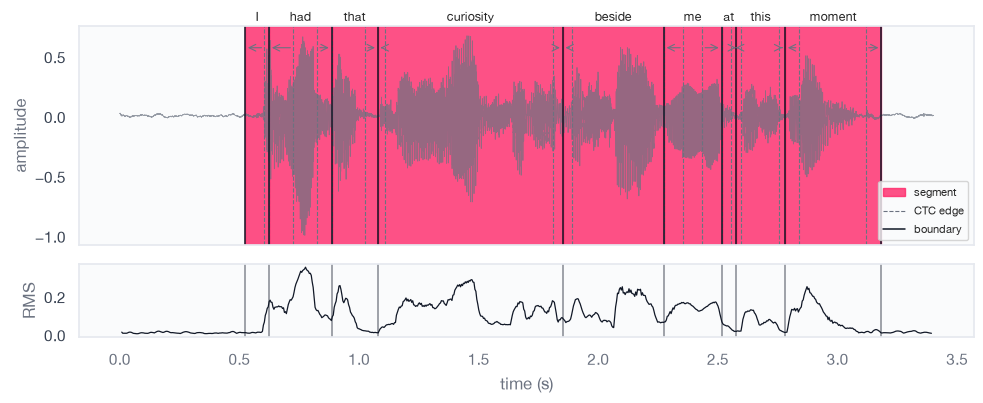

In [7]:
spoken = Message(role=Role.USER, content=(TextPart(TRANSCRIPT), audio))
snapshot = ConversationSnapshot.from_turns((Turn(messages=(spoken,)),))
config = ExplainConfig.model_validate({
    "backend": {"kind": "mock", "model_id": "stub"},
    "explanation": {
        "players": "sgpa_segments",
        "archive": {"path": ""},
        "plugin_options": {"sgpa_segments": {"model_id": MODEL_ID, "revision": REVISION}},
    },
})
output = await ExplainRunner(config).explain(snapshot)
for span, value in zip(output.player_set.spans, output.result.values):
    print(f"{span.text:10} samples={span.samples} value={value:+.3f}")
print("efficiency:", round(sum(output.result.values), 6),
      round(output.result.grand_value - output.result.base_value, 6))
plot_audio_segments(audio, segments, values=list(output.result.values));

## Masked audio

Absence policies edit the transcript and the audio together: `delete` cuts the absent words' samples, `pad` and `neutral` keep the length and silence them.

In [8]:
players = SgpaSegmentPartitioner(aligner=aligner).partition(snapshot)
keep_first_half = CoalitionMask(tuple(i < 4 for i in range(players.num_players)))
for policy in (DeletePolicy(), NeutralPolicy()):
    rendered = policy.apply(snapshot, players, keep_first_half).turns[0].messages[0]
    samples, rate = decode_audio(rendered.content[1].data())
    print(f"{policy.name:8} {len(samples) / rate:.2f} s | {rendered.text}")

delete   2.07 s | I had that curiosity
neutral  3.40 s | I had that curiosity ______ __ __ ____ ______
